In [15]:
import sys
print(sys.executable)

c:\Users\LENOVO\OneDrive\Documents\CACD Project\ransomware-defense\venv\Scripts\python.exe


In [16]:
import pandas as pd
import numpy as np
import sklearn
import matplotlib

print("All libraries imported successfully!")

All libraries imported successfully!


In [17]:
import pandas as pd

X_train = pd.read_csv("../dataset/raw/MLRan_X_train_RFE.csv")

print("Dataset shape:", X_train.shape)
display(X_train.head())

Dataset shape: (3905, 487)


,sample_id,sample_type,family_label,type_label,5,8,18,32,33,34,...,6468165,6468166,6468169,6468170,6468193,6468195,6468200,6468202,6468204,6468211
0,10001,1,3,2,1,1,1,1,1,1,...,0,0,0,0,0,0,0,0,0,0
1,10002,1,12,2,1,1,1,0,0,1,...,0,0,0,0,0,0,0,0,1,0
2,10003,1,3,2,0,0,1,0,0,1,...,0,0,0,0,0,0,0,0,0,0
3,10004,1,9,1,1,0,1,1,0,1,...,0,0,0,0,0,0,0,0,1,0
4,10005,1,11,1,1,1,1,1,1,1,...,1,1,1,1,0,0,1,0,0,0


In [18]:
y_train = X_train["sample_type"]

X_features = X_train.drop(
    columns=["sample_id", "sample_type", "family_label", "type_label"]
)

print("Feature shape:", X_features.shape)
print("Target shape:", y_train.shape)
print("\nClass counts:")
print(y_train.value_counts())

Feature shape: (3905, 483)
Target shape: (3905,)

Class counts:
sample_type
0    2040
1    1865
Name: count, dtype: int64


In [19]:
import pandas as pd

X_test = pd.read_csv("../dataset/raw/MLRan_X_test_RFE.csv")

print("Test dataset shape:", X_test.shape)
print(X_test.head())

Test dataset shape: (975, 487)
   sample_id  sample_type  family_label  type_label  5  8  18  32  33  34  \
0      11027            1             8           1  1  1   1   1   1   1   
1      11030            1            31           2  1  0   1   0   1   1   
2      11033            1             8           1  1  1   1   1   1   1   
3      11035            1             8           1  1  1   1   1   1   1   
4      11036            1             3           2  1  1   1   0   0   1   

   ...  6468165  6468166  6468169  6468170  6468193  6468195  6468200  \
0  ...        1        0        1        1        0        0        0   
1  ...        0        1        0        0        0        0        1   
2  ...        1        0        1        1        0        0        0   
3  ...        0        0        0        0        0        0        0   
4  ...        0        0        0        0        0        0        0   

   6468202  6468204  6468211  
0        0        1        1  
1    

In [20]:
y_test = X_test["sample_type"]

X_test_features = X_test.drop(
    columns=["sample_id", "sample_type", "family_label", "type_label"]
)

print("Test feature shape:", X_test_features.shape)
print("Test target shape:", y_test.shape)

# Verify that training and test features match
print("Same feature columns:", 
      list(X_features.columns) == list(X_test_features.columns))

Test feature shape: (975, 483)
Test target shape: (975,)
Same feature columns: True


In [21]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

model.fit(X_features, y_train)

print("Random Forest training completed!")

Random Forest training completed!


Accuracy: 0.9713

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.97      0.97       510
           1       0.96      0.98      0.97       465

    accuracy                           0.97       975
   macro avg       0.97      0.97      0.97       975
weighted avg       0.97      0.97      0.97       975

Confusion Matrix:
[[493  17]
 [ 11 454]]


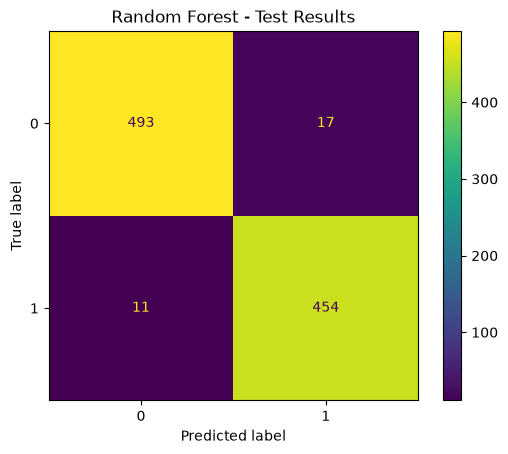

In [22]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

y_pred = model.predict(X_test_features)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(cm)

ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
plt.title("Random Forest - Test Results")
plt.show()

In [23]:
import joblib
from pathlib import Path

Path("../models").mkdir(parents=True, exist_ok=True)

joblib.dump(model, "../models/random_forest_baseline.joblib")

print("Model saved successfully!")

Model saved successfully!


In [24]:
import pandas as pd
import matplotlib.pyplot as plt

importance_df = pd.DataFrame({
    "feature": X_features.columns,
    "importance": model.feature_importances_
})

importance_df = importance_df.sort_values(
    "importance", ascending=False
)

display(importance_df.head(20))

,feature,importance
190,2944930,0.040930
433,6413348,0.039393
405,6412331,0.035417
133,214391,0.030999
85,119780,0.028992
96,140099,0.025225
97,140100,0.021756
64,35566,0.019989
2,18,0.018046
77,100647,0.017742


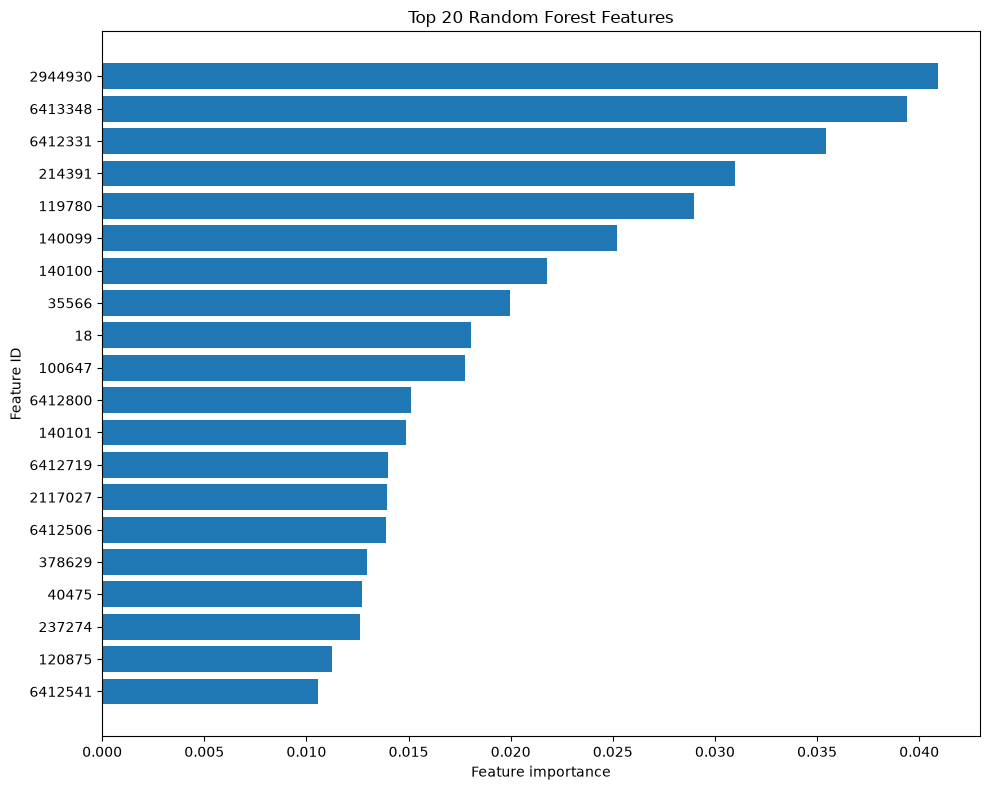

In [25]:
top20 = importance_df.head(20).sort_values("importance")

plt.figure(figsize=(10, 8))
plt.barh(top20["feature"].astype(str), top20["importance"])
plt.xlabel("Feature importance")
plt.ylabel("Feature ID")
plt.title("Top 20 Random Forest Features")
plt.tight_layout()
plt.show()

In [26]:
import json
from pathlib import Path

json_path = Path(
    "../dataset/raw/RFE_selected_feature_names_dic.json"
)

print("Mapping file exists:", json_path.exists())

Mapping file exists: False


In [27]:
from pathlib import Path

raw_folder = Path("../dataset/raw")

print("Raw folder exists:", raw_folder.exists())

if raw_folder.exists():
    for file in raw_folder.iterdir():
        print(file.name)

Raw folder exists: True
MLRan_labels.csv
MLRan_X_test_RFE.csv
MLRan_X_train_RFE.csv
type_test_sampleids.csv
type_train_sampleids.csv


In [28]:
from pathlib import Path

Path("../dataset/processed").mkdir(parents=True, exist_ok=True)

importance_df.head(20).to_csv(
    "../dataset/processed/top20_feature_importance.csv",
    index=False
)

print("Top 20 feature importance saved!")

Top 20 feature importance saved!
